# Figure 2A–C: Template Registration and Method Comparison

This notebook compares **O2-Column vs O3** and **O2-FS vs O3** using the same subject manifest, anatomical mask, canonical depth convention, and curvature definition.

Scientific questions:

1. Does each alternative method preserve the 21-depth profile shape obtained with O3?
2. Does the absolute MD-profile difference increase with local cortical curvature?
3. What is the quality of the shared T1-to-DWI boundary-based registration across the processed cohort?

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Image, Markdown, display
from nilearn import plotting

RANDOM_SEED = 20261020
MIN_VALID_SUBJECT_FRACTION = 0.80
N_CURVATURE_BINS = 10
CORRELATION_VMIN = 0.80
CORRELATION_VMAX = 1.00
RUN_VERTEX_ANALYSIS = False
REBUILD_SURFACE_FIGURES = False
RUN_REGISTRATION_QC = False

np.random.seed(RANDOM_SEED)

def find_repo_root(start):
    current = start.resolve()
    for candidate in (current, *current.parents):
        if (candidate / '.git').exists():
            return candidate
    raise RuntimeError('Could not locate the repository root')


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure,
    set_publication_style, style_axes,
)
set_publication_style()
PROJECT_ROOT = REPO_ROOT.parents[1]
RESULTS_ROOT = PROJECT_ROOT / 'results'
FREESURFER_SUBJECTS_DIR = (
    PROJECT_ROOT / 'data' / 'processed' / 't1_freesurfer'
)
SUBJECTS_FILE = REPO_ROOT / 'manifests' / 'o2_fs_50_fsaverage_subjects.txt'
REGISTRATION_COHORT_MANIFEST = (
    REPO_ROOT / 'manifests' / 'registration_qc_adrc_subjects.csv'
)
ANALYSIS_SCRIPT = (
    REPO_ROOT
    / 'analysis_results'
    / 'figure2'
    / 'figure2_method_comparison.py'
)
REGISTRATION_QC_SCRIPT = (
    REPO_ROOT
    / 'analysis_results'
    / 'figure2'
    / 'figure2_registration_qc.py'
)
SUBJECT_LEVEL_2B_SCRIPT = (
    REPO_ROOT
    / 'analysis_results'
    / 'figure2'
    / 'figure2b_subject_level.py'
)
OUTPUT_DIR = (
    RESULTS_ROOT
    / 'qc'
    / 'template_registration_comparison'
    / 'figure2_method_comparison_fsaverage'
)
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

COMPARISONS = {
    'O2Column_vs_O3': 'O2-Column vs O3',
    'O2FS_vs_O3': 'O2-FS vs O3',
}
HEMISPHERES = ('lh', 'rh')

print(f'Repository: {REPO_ROOT}')
print(f'Output directory: {OUTPUT_DIR}')

Repository: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis
Output directory: /mnt/newStor/paros/paros_WORK/xintong/results/qc/template_registration_comparison/figure2_method_comparison_fsaverage


## 2. Definition of O2-Column, O2-FS, and O3

- **O2-Column:** MD is first sampled along three native paired pial-white columns. The resulting profile values are then combined using the target triangle's barycentric weights.
- **O2-FS:** FreeSurfer volume-to-surface depth sampling and spherical surface resampling produce 21-point profiles on fsaverage.
- **O3:** Native white and pial endpoints are first interpolated with barycentric weights. A subject-specific target column is then constructed and sampled from the MD volume.

Figure 2A tests agreement in **profile shape**. Figure 2B tests whether the **absolute MD difference** depends on local cortical curvature. Correlation is insensitive to overall offset and scale, so Figure 2B is a necessary complement to Figure 2A.

## 3. Input data and depth convention

The analysis reads the subject manifest rather than hard-coding the cohort size. Every loader aligns rows explicitly by `target_vertex_id`. Profiles must contain 21 depths including both endpoints.

The canonical convention is **depth 0 = pial, depth 1 = white** (`pial_to_white`). Direction is read from each profile file. A profile is reversed only when its metadata explicitly states `white_to_pial`; missing or ambiguous metadata is treated as an error. The current O3 generation code and profile metadata use `pial_to_white`, even though an older README described the opposite direction.

In [2]:
subjects = [
    line.strip()
    for line in SUBJECTS_FILE.read_text().splitlines()
    if line.strip() and not line.startswith('#')
]

required_outputs = [
    OUTPUT_DIR / 'figure2_O2Column_vs_O3_vertex_metrics.parquet',
    OUTPUT_DIR / 'figure2_O2FS_vs_O3_vertex_metrics.parquet',
    OUTPUT_DIR / 'figure2_pairwise_coverage_qc.csv',
    OUTPUT_DIR / 'figure2_analysis_manifest.csv',
    OUTPUT_DIR / 'figure2_curvature_bins.csv',
    OUTPUT_DIR / 'figure2_curvature_cross_subject_summary.csv',
]
missing_outputs = [path for path in required_outputs if not path.is_file()]
if not missing_outputs:
    for comparison in COMPARISONS:
        metric_path = OUTPUT_DIR / f'figure2_{comparison}_vertex_metrics.parquet'
        if 'profile_snmae_pct' not in pq.ParquetFile(metric_path).schema.names:
            missing_outputs.append(metric_path)

if RUN_VERTEX_ANALYSIS or missing_outputs:
    command = [
        sys.executable,
        '-u',
        str(ANALYSIS_SCRIPT),
        '--method-a',
        'O2-Column',
        '--method-b',
        'O3',
        '--run-both',
        '--results-root',
        str(RESULTS_ROOT),
        '--freesurfer-subjects-dir',
        str(FREESURFER_SUBJECTS_DIR),
        '--subjects-file',
        str(SUBJECTS_FILE),
        '--output-dir',
        str(OUTPUT_DIR),
    ]
    subprocess.run(command, check=True, cwd=REPO_ROOT)

remaining_missing = [path for path in required_outputs if not path.is_file()]
if remaining_missing:
    raise FileNotFoundError(f'Missing required outputs: {remaining_missing}')

subject_level_2b_outputs = [
    OUTPUT_DIR / 'figure2_subject_spearman.csv',
    OUTPUT_DIR / 'figure2_subject_spearman_summary.csv',
]
missing_subject_level_2b = [
    path for path in subject_level_2b_outputs if not path.is_file()
]
if missing_subject_level_2b:
    subprocess.run(
        [
            sys.executable, '-u', str(SUBJECT_LEVEL_2B_SCRIPT),
            '--input-dir', str(OUTPUT_DIR),
            '--output-dir', str(OUTPUT_DIR),
        ],
        check=True, cwd=REPO_ROOT,
    )

print(f'Manifest subjects: {len(subjects)}')
print('All required cached analysis outputs are available.')

Manifest subjects: 50
All required cached analysis outputs are available.


## 4. Common analysis mask and validity checks

The anatomical mask is `fsaverage cortex.label ∩ valid DK cortical labels`. Each primary comparison then intersects this mask with the two methods' complete 21-depth validity and finite-value masks. A three-method common mask is also retained as a coverage sensitivity check. The primary analysis remains pairwise; it is never silently replaced by the three-method mask.

In [3]:
coverage = pd.read_csv(OUTPUT_DIR / 'figure2_pairwise_coverage_qc.csv')
manifest = pd.read_csv(OUTPUT_DIR / 'figure2_analysis_manifest.csv')
curvature_edges = pd.read_csv(OUTPUT_DIR / 'figure2_curvature_bins.csv')

coverage_summary = (
    coverage.groupby('comparison', as_index=False)
    .agg(
        n_subjects=('subject_id', 'nunique'),
        n_hemispheres=('hemisphere', 'size'),
        mean_pairwise_coverage_pct=('pairwise_valid_percentage', 'mean'),
        minimum_pairwise_coverage_pct=('pairwise_valid_percentage', 'min'),
        n_undefined_profile_correlations=(
            'n_undefined_profile_correlation',
            'sum',
        ),
        median_three_method_common_valid=(
            'n_three_method_common_valid',
            'median',
        ),
    )
)
display(coverage_summary.round(3))
display(curvature_edges)

excluded = manifest.loc[~manifest['hemisphere_included'].astype(bool)]
print(f'Excluded subject-hemisphere records: {len(excluded)}')

,comparison,n_subjects,n_hemispheres,mean_pairwise_coverage_pct,minimum_pairwise_coverage_pct,n_undefined_profile_correlations,median_three_method_common_valid
0,O2Column_vs_O3,50,100,98.297,80.136,0,147966.5
1,O2FS_vs_O3,50,100,98.706,90.134,12706,147966.5


,curvature_bin,binning_method,n_bins_requested
0,0,subject_specific_equal_frequency,10
1,1,subject_specific_equal_frequency,10
2,2,subject_specific_equal_frequency,10
3,3,subject_specific_equal_frequency,10
4,4,subject_specific_equal_frequency,10
5,5,subject_specific_equal_frequency,10
6,6,subject_specific_equal_frequency,10
7,7,subject_specific_equal_frequency,10
8,8,subject_specific_equal_frequency,10
9,9,subject_specific_equal_frequency,10


Excluded subject-hemisphere records: 0


## 5. Figure 2A: Per-vertex profile correlation

For every pairwise-valid subject, hemisphere, and target vertex, Pearson correlation is calculated between the two 21-depth profiles. Constant profiles produce undefined correlation and are retained in QC but excluded from Fisher averaging. Valid correlations are clipped to `[-0.999999, 0.999999]`, transformed with Fisher z, averaged across subjects, and transformed back.

Only vertices with at least the configured valid-subject fraction are displayed. This coverage threshold prevents a group-level surface value based on only a small number of subjects from appearing as reliable as a value supported by most of the cohort. The denominator is the number of subjects included in that method comparison, and a subject contributes only when that vertex has a defined profile correlation. This criterion affects surface-map display only: all subject-level and vertex-level results remain in the saved tables. Vertices below the threshold are shown as missing rather than assigned a correlation value. LH and RH use their own meshes but share one colormap and color range.

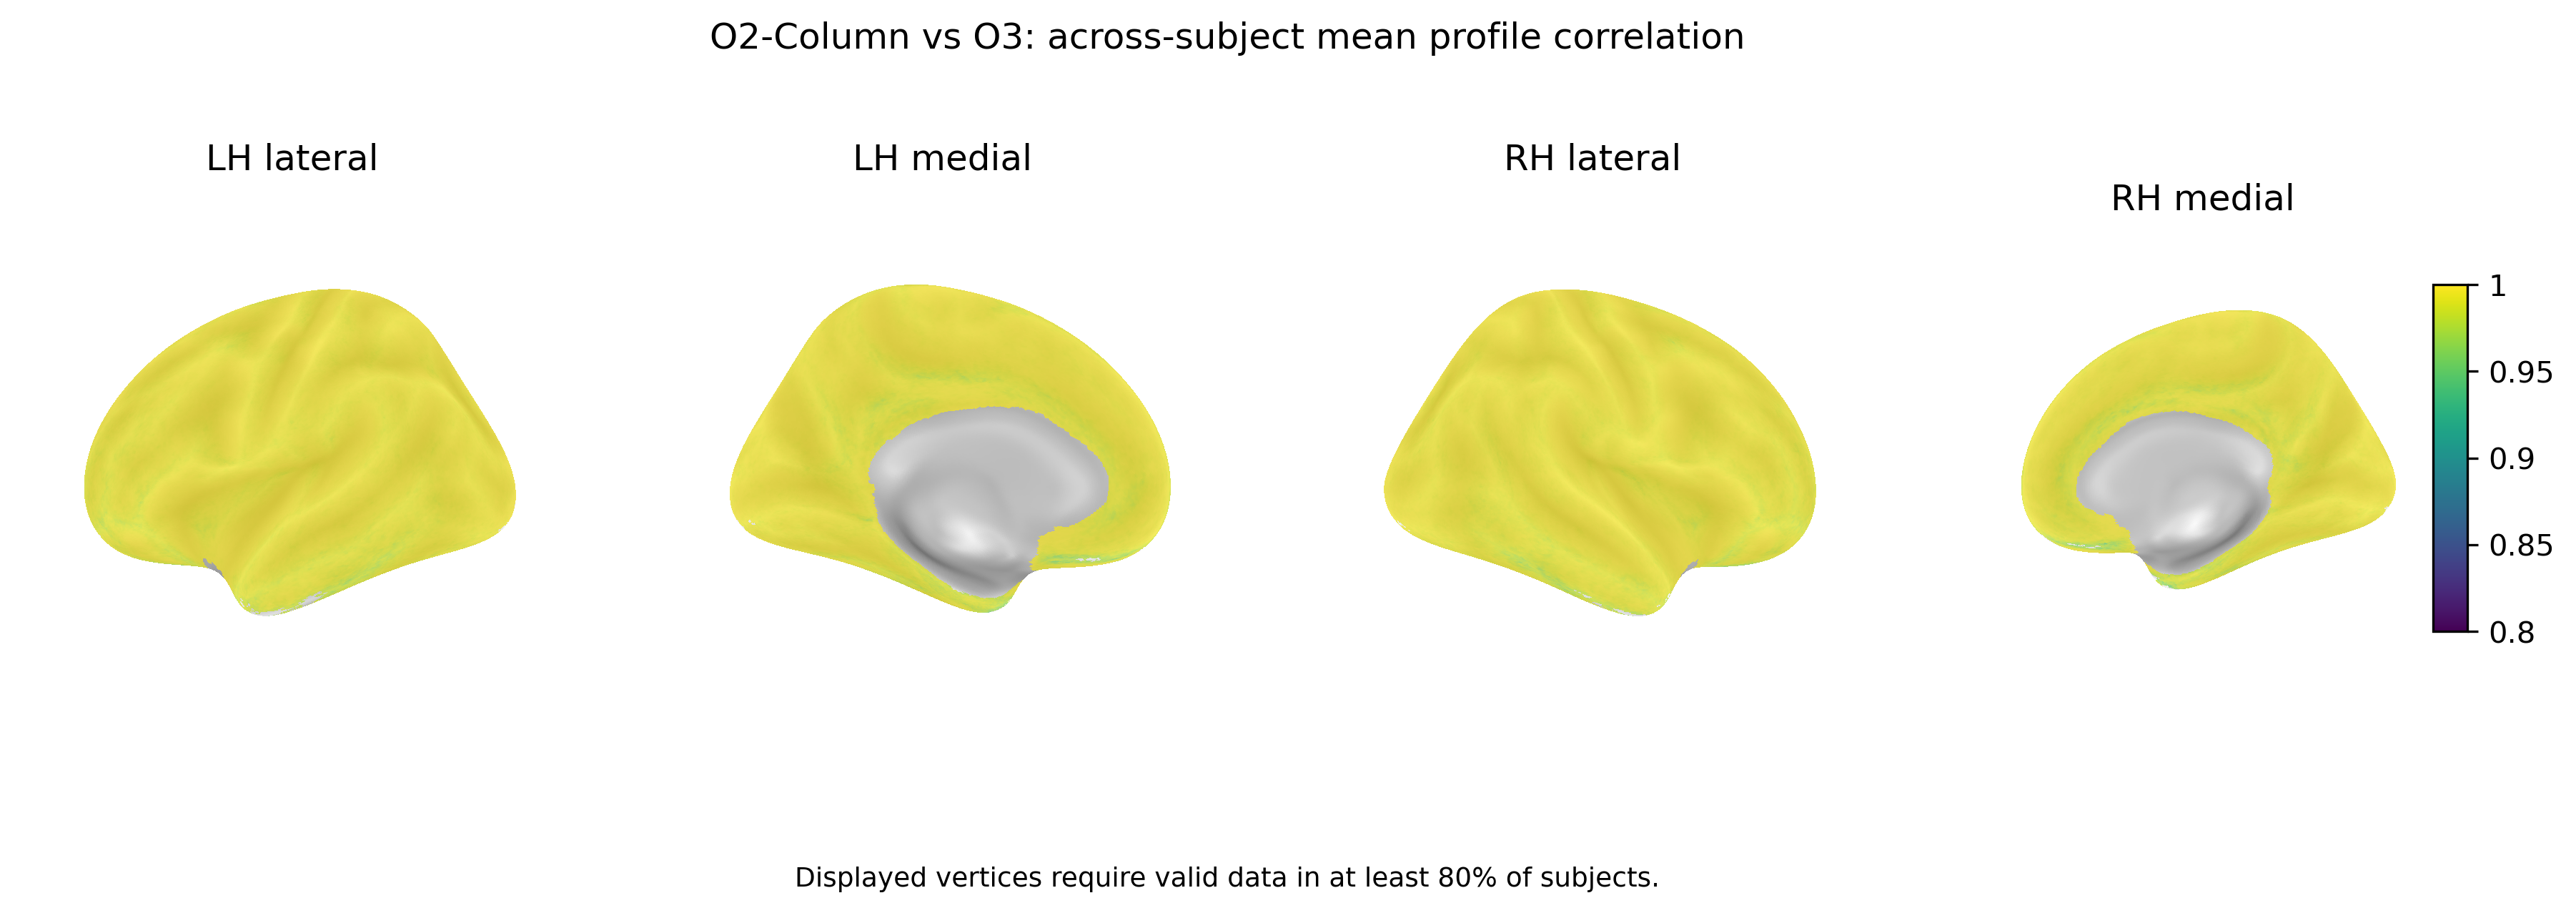

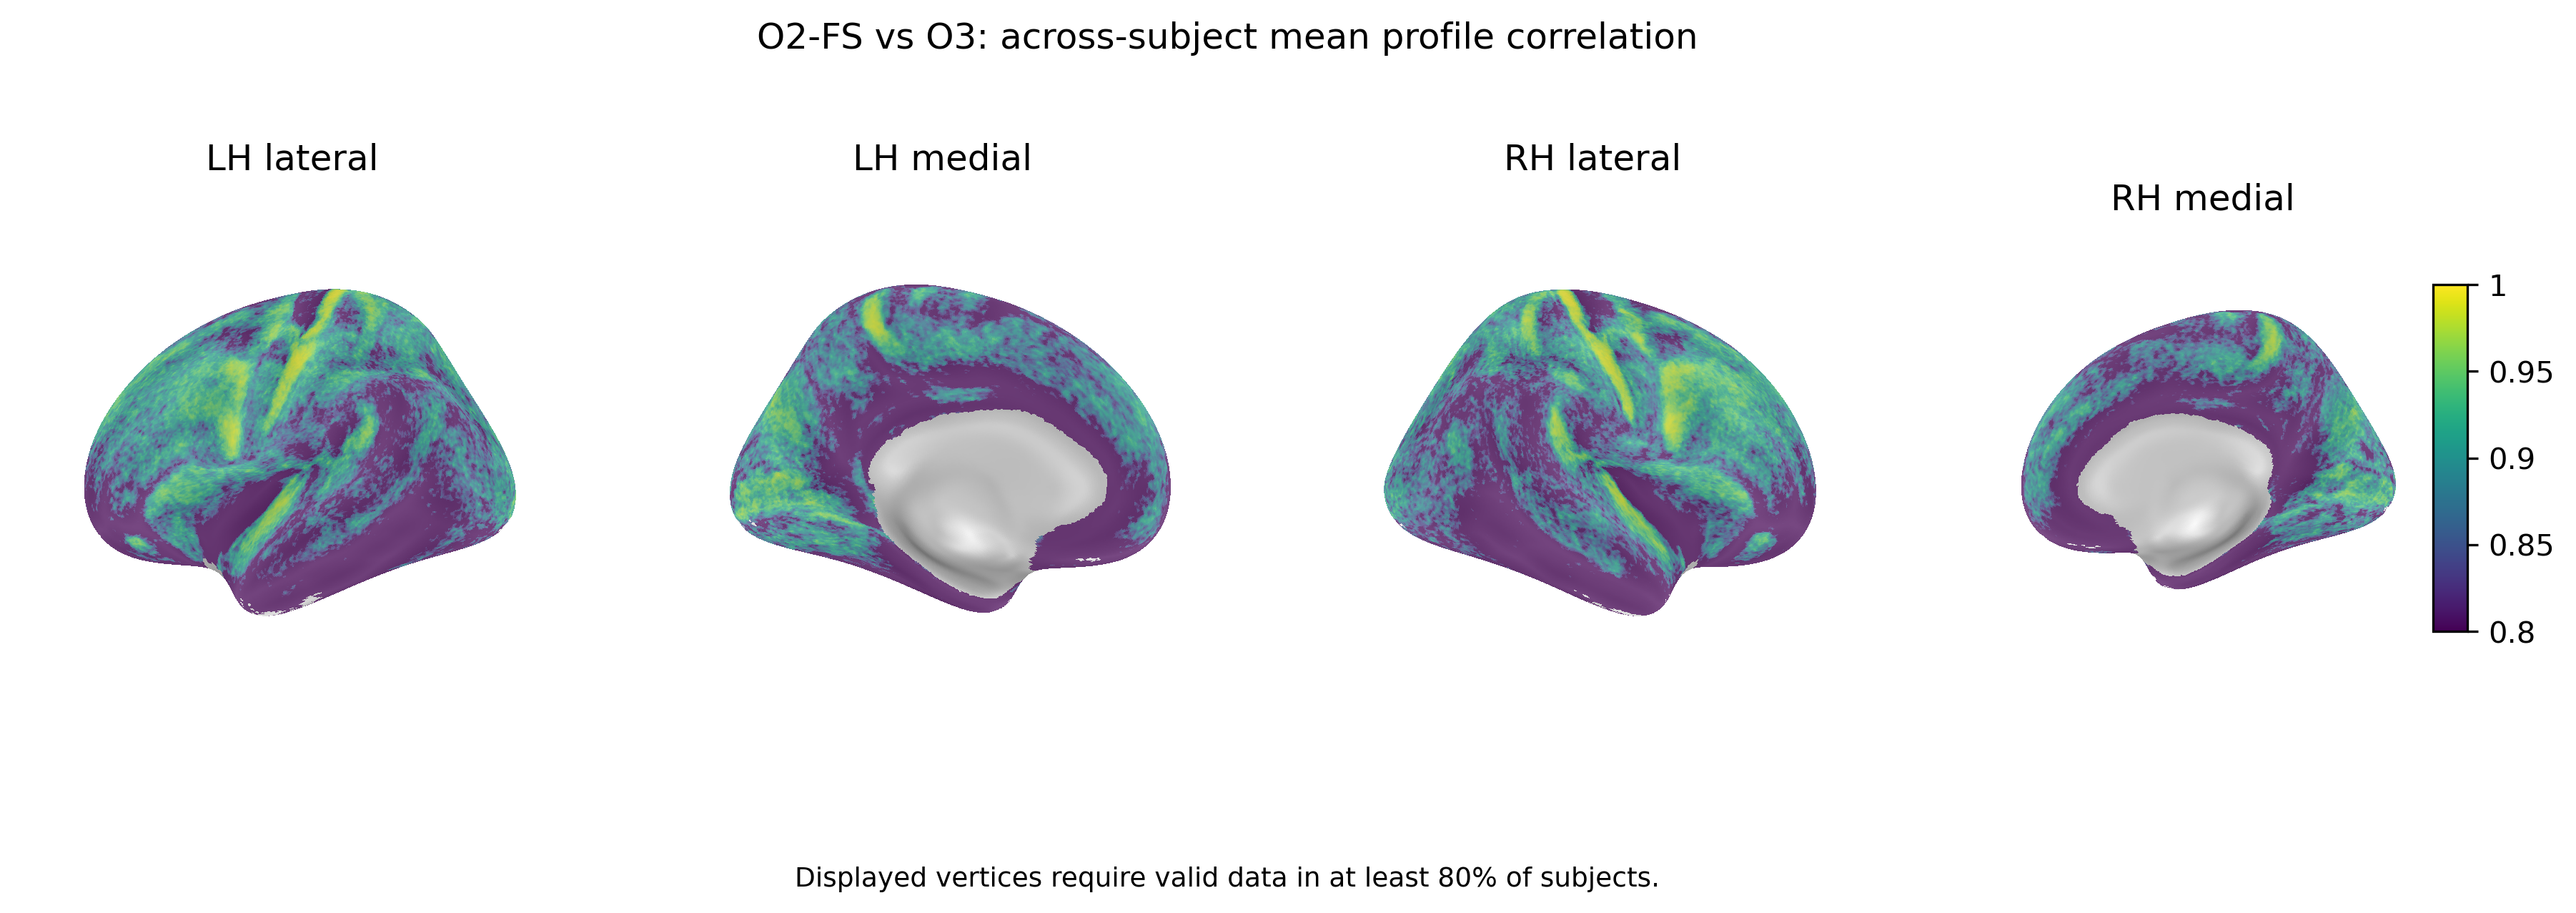

In [4]:
def load_surface_summary(comparison, hemisphere):
    path = (
        OUTPUT_DIR
        / f'figure2_{comparison}_vertex_agreement_map_{hemisphere}.csv'
    )
    return pd.read_csv(path)


def plot_agreement_surface(comparison, label):
    png_path = FIGURE_DIR / f'Figure2A_{comparison}_inflated.png'
    pdf_path = FIGURE_DIR / f'Figure2A_{comparison}_inflated.pdf'
    if (
        not REBUILD_SURFACE_FIGURES
        and png_path.is_file()
        and pdf_path.is_file()
    ):
        display(Image(filename=str(png_path)))
        return

    views = [
        ('lh', 'left', 'lateral'),
        ('lh', 'left', 'medial'),
        ('rh', 'right', 'lateral'),
        ('rh', 'right', 'medial'),
    ]
    fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 2.45))
    surface_cmap = plt.colormaps['project_blue'].copy()
    surface_cmap.set_bad(PALETTE['masked'])

    for index, (hemisphere, nilearn_hemi, view) in enumerate(views):
        summary = load_surface_summary(comparison, hemisphere)
        n_vertices = int(summary['target_vertex_id'].max()) + 1
        stat_map = np.full(n_vertices, np.nan, dtype=float)
        eligible = (
            summary['valid_subject_fraction']
            >= MIN_VALID_SUBJECT_FRACTION
        )
        vertex_ids = summary.loc[eligible, 'target_vertex_id'].to_numpy(int)
        stat_map[vertex_ids] = summary.loc[
            eligible,
            'mean_profile_r_fisher',
        ].to_numpy()

        mesh = (
            FREESURFER_SUBJECTS_DIR
            / 'fsaverage'
            / 'surf'
            / f'{hemisphere}.inflated'
        )
        sulc = mesh.with_name(f'{hemisphere}.sulc')
        axis = fig.add_subplot(1, 4, index + 1, projection='3d')
        plotting.plot_surf_stat_map(
            str(mesh),
            stat_map,
            hemi=nilearn_hemi,
            view=view,
            bg_map=str(sulc),
            bg_on_data=True,
            darkness=0.55,
            cmap=surface_cmap,
            vmin=CORRELATION_VMIN,
            vmax=CORRELATION_VMAX,
            colorbar=index == 3,
            axes=axis,
            figure=fig,
            title=None,
        )

    save_publication_figure(fig, png_path.with_suffix(''))
    plt.show()


for comparison, label in COMPARISONS.items():
    plot_agreement_surface(comparison, label)

### Figure 2A2: Subject-level quantitative agreement

Each point is one subject. For each comparison, LH and RH are pooled and the subject value is the median across all pairwise-valid fsaverage vertices (with defined profile correlation where applicable). The box marks the group IQR and median; the violin shows the subject distribution. sNMAE complements correlation because correlation can have a ceiling effect: it is the symmetric normalized profile MAE, `200 × MAE / (median(|A|) + median(|B|))`, expressed as a percentage.

,comparison_label,metric,n_subjects,group_median,group_q25,group_q75
0,O2-Column vs O3,Profile correlation,50,0.996497,0.995349,0.997169
1,O2-Column vs O3,sNMAE (%),50,1.957145,1.807125,2.396821
2,O2-FS vs O3,Profile correlation,50,0.870392,0.845704,0.902817
3,O2-FS vs O3,sNMAE (%),50,16.557108,15.408177,18.793826


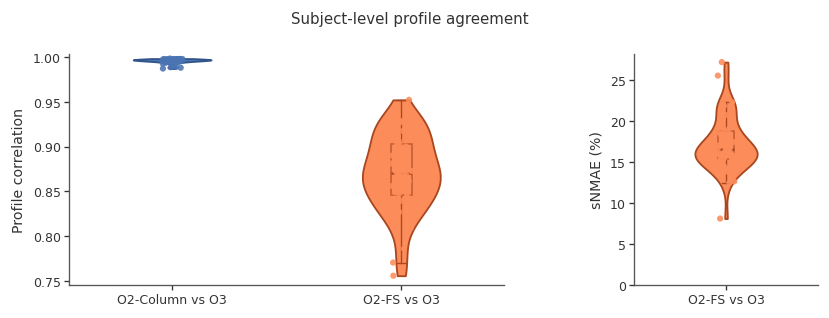

In [5]:
def summarize_subject_profile_metrics(comparison):
    metric_path = OUTPUT_DIR / f'figure2_{comparison}_vertex_metrics.parquet'
    metrics = pq.read_table(
        metric_path,
        columns=[
            'subject_id',
            'pairwise_valid',
            'profile_r',
            'profile_snmae_pct',
        ],
    ).to_pandas()
    valid = metrics['pairwise_valid'].astype(bool)
    rows = []
    for metric, label in (
        ('profile_r', 'Profile correlation'),
        ('profile_snmae_pct', 'sNMAE (%)'),
    ):
        subset = metrics.loc[valid & metrics[metric].notna()]
        summary = subset.groupby('subject_id')[metric].agg(
            median='median',
            n_valid_vertices='size',
        ).reset_index()
        summary['comparison'] = comparison
        summary['metric'] = label
        summary = summary.rename(columns={'median': 'subject_median'})
        rows.append(summary)
    return pd.concat(rows, ignore_index=True)


subject_agreement = pd.concat(
    [summarize_subject_profile_metrics(name) for name in COMPARISONS],
    ignore_index=True,
)
subject_agreement['comparison_label'] = subject_agreement['comparison'].map(COMPARISONS)
subject_agreement.to_csv(
    OUTPUT_DIR / 'figure2A_subject_level_profile_agreement.csv',
    index=False,
)


def plot_subject_agreement(summary):
    subject_colors = {
        'O2Column_vs_O3': PALETTE['blue'],
        'O2FS_vs_O3': PALETTE['orange'],
    }
    specs = (
        ('Profile correlation', 'Profile correlation'),
        ('sNMAE (%)', 'sNMAE (%)'),
    )
    figures = []
    for comparison, comparison_label in COMPARISONS.items():
        figure, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH_IN, 2.75))
        for axis, (metric, ylabel) in zip(axes, specs):
            values = summary.loc[
                summary['comparison'].eq(comparison)
                & summary['metric'].eq(metric),
                'subject_median',
            ].dropna().to_numpy()
            violin = axis.violinplot(
                [values], positions=[1], showmeans=False, showmedians=False,
            )
            violin['bodies'][0].set_facecolor(subject_colors[comparison])
            violin['bodies'][0].set_edgecolor('none')
            violin['bodies'][0].set_alpha(0.32)
            box = axis.boxplot(
                [values], positions=[1], widths=0.24, patch_artist=True,
                showfliers=False, medianprops={'color': 'black', 'linewidth': 1.5},
            )
            box['boxes'][0].set_facecolor(subject_colors[comparison])
            box['boxes'][0].set_alpha(0.75)
            jitter = np.random.default_rng(20261020).uniform(
                -0.055, 0.055, size=values.size,
            )
            axis.scatter(
                1 + jitter, values, s=15, color=subject_colors[comparison],
                edgecolor='white', linewidth=0.35, zorder=3, alpha=0.9,
            )
            q25, median, q75 = np.quantile(values, [0.25, 0.5, 0.75])
            precision = 4 if metric == 'Profile correlation' else 2
            axis.text(
                1, 0.98,
                f'median {median:.{precision}f}\nIQR {q25:.{precision}f}–{q75:.{precision}f}',
                transform=axis.get_xaxis_transform(), ha='center', va='top',
                fontsize=7.5,
            )
            axis.set_xlim(0.6, 1.4)
            axis.set_xticks([1], [comparison_label], fontsize=8)
            axis.set_ylabel(ylabel)
            style_axes(axis, grid=True)
            if metric == 'Profile correlation':
                axis.set_ylim(max(-1.0, values.min() - 0.003), 1.002)
            else:
                axis.set_ylim(bottom=0)
        figure.tight_layout()
        save_publication_figure(
            figure, FIGURE_DIR / f'Figure2A2_{comparison}_subject_level_profile_agreement'
        )
        figures.append(figure)
    return figures


subject_agreement_summary = (
    subject_agreement.groupby(['comparison_label', 'metric'], as_index=False)
    .agg(
        n_subjects=('subject_id', 'nunique'),
        group_median=('subject_median', 'median'),
        group_q25=('subject_median', lambda values: values.quantile(0.25)),
        group_q75=('subject_median', lambda values: values.quantile(0.75)),
    )
)
display(subject_agreement_summary.round(6))
plot_subject_agreement(subject_agreement)
plt.show()

### Figure 2A interpretation guide

- Correlation near 1 indicates highly consistent depth-profile shape.
- Lower-correlation regions indicate local differences in recovered profile shape.
- High correlation does not imply identical absolute MD values; Figure 2B addresses magnitude differences.
- Constant or nearly constant profiles can make correlation undefined or unstable and should be interpreted with profile MAE and profile SD.

## 7. Figure 2B: Profile MAE versus absolute mean curvature

The y-axis is the mean absolute difference between two 21-depth MD profiles. The x-axis is O3 target curvature calculated as the barycentric interpolation of the absolute native white-surface curvature values: `sum(w_i * abs(H_i))`. It is a shared geometric variable, not a difference in curvature between methods.

For the curve, LH and RH valid vertices are pooled **within each subject**, then split into ten subject-specific equal-frequency curvature bins. Each subject contributes one median MAE per bin; the plotted group median and IQR therefore weight subjects equally. Separately, one Spearman correlation is calculated per subject between vertex-wise absolute curvature and profile MAE, then summarized across subjects with a bootstrap 95% CI and Wilcoxon signed-rank test.

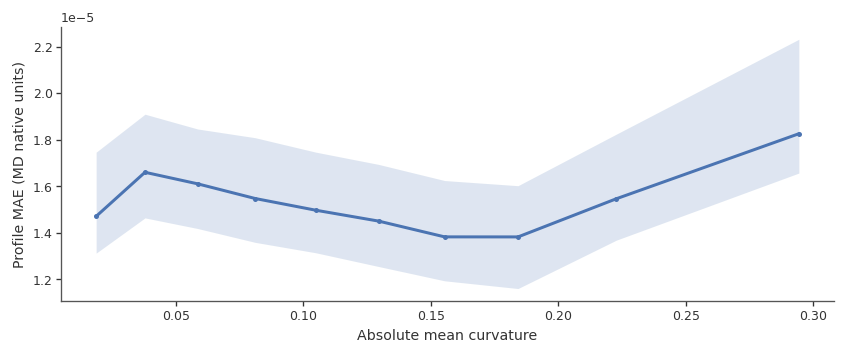

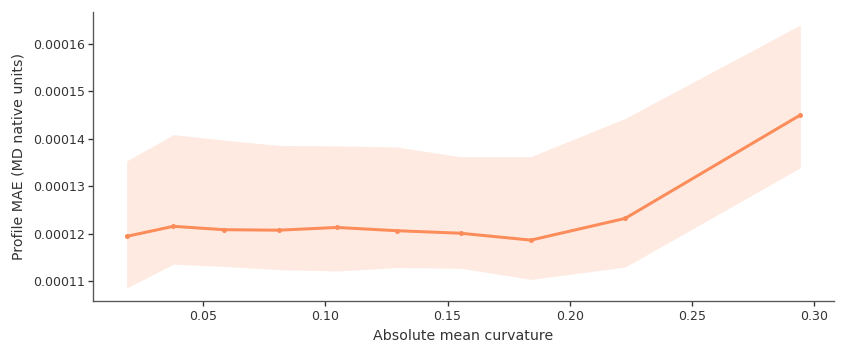

,comparison,n_subjects,median_spearman_rho,q25_spearman_rho,q75_spearman_rho,bootstrap_ci95_low,bootstrap_ci95_high,wilcoxon_statistic,wilcoxon_p_value,n_bootstrap
0,O2Column_vs_O3,50,0.019080,0.001379,0.033793,0.007333,0.025661,135.0,0.0,10000
1,O2FS_vs_O3,50,0.039205,0.019299,0.061406,0.030822,0.046250,9.0,0.0,10000


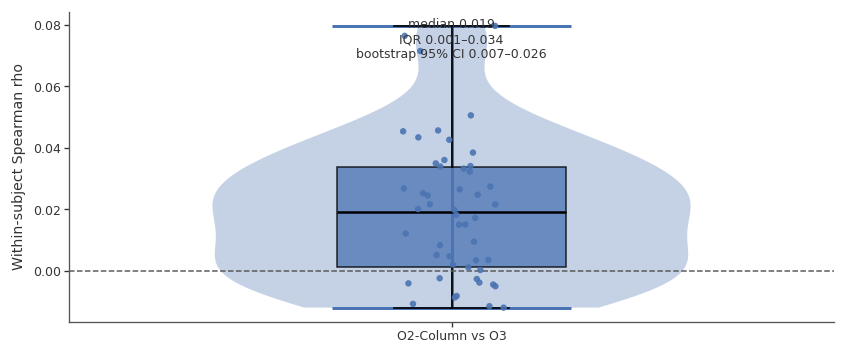

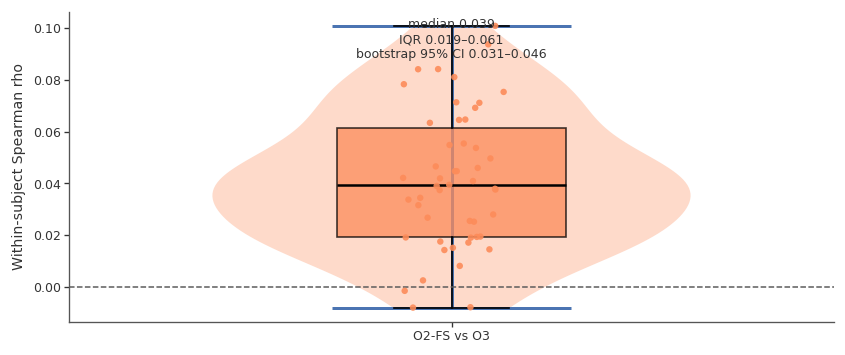

In [6]:
curvature_summary = pd.read_csv(
    OUTPUT_DIR / "figure2_curvature_cross_subject_summary.csv"
)
subject_spearman = pd.read_csv(OUTPUT_DIR / 'figure2_subject_spearman.csv')
subject_spearman_summary = pd.read_csv(
    OUTPUT_DIR / 'figure2_subject_spearman_summary.csv'
)
colors = {
    "O2Column_vs_O3": PALETTE['blue'],
    "O2FS_vs_O3": PALETTE['orange'],
}

for comparison, label in COMPARISONS.items():
    part = (
        curvature_summary.loc[
            curvature_summary["comparison"].eq(comparison)
        ]
        .sort_values("curvature_bin")
    )
    x = part["median_curvature_across_subjects"].to_numpy()
    y = part["median_mae_across_subjects"].to_numpy()
    lower = part["q25_mae_across_subjects"].to_numpy()
    upper = part["q75_mae_across_subjects"].to_numpy()

    fig, axis = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.0))
    axis.plot(
        x,
        y,
        marker="o",
        linewidth=1.8,
        color=colors[comparison],
    )
    axis.fill_between(
        x,
        lower,
        upper,
        color=colors[comparison],
        alpha=0.18,
        linewidth=0,
    )
    axis.set_xlabel("Absolute mean curvature")
    axis.set_ylabel("Profile MAE (MD native units)")
    style_axes(axis, grid=True)
    fig.tight_layout()

    filename = f"Figure2B_{comparison}_MAE_vs_curvature"
    save_publication_figure(fig, FIGURE_DIR / filename)
    plt.show()

display(subject_spearman_summary.round(6))
for comparison, label in COMPARISONS.items():
    values = subject_spearman.loc[
        subject_spearman['comparison'].eq(comparison), 'spearman_rho'
    ].dropna().to_numpy()
    result = subject_spearman_summary.loc[
        subject_spearman_summary['comparison'].eq(comparison)
    ].iloc[0]
    fig, axis = plt.subplots(figsize=(FIGURE_WIDTH_IN, 3.0))
    violin = axis.violinplot([values], positions=[1], showmedians=False)
    violin['bodies'][0].set_facecolor(colors[comparison])
    violin['bodies'][0].set_edgecolor('none')
    violin['bodies'][0].set_alpha(0.32)
    box = axis.boxplot(
        [values], positions=[1], widths=0.24, patch_artist=True,
        showfliers=False, medianprops={'color': 'black', 'linewidth': 1.5},
    )
    box['boxes'][0].set_facecolor(colors[comparison])
    box['boxes'][0].set_alpha(0.75)
    jitter = np.random.default_rng(RANDOM_SEED).uniform(-0.055, 0.055, values.size)
    axis.scatter(
        1 + jitter, values, s=15, color=colors[comparison], edgecolor='white',
        linewidth=0.35, zorder=3, alpha=0.9,
    )
    axis.axhline(0, color='0.35', linewidth=0.9, linestyle='--')
    axis.set_xlim(0.6, 1.4)
    axis.set_xticks([1], [label])
    axis.set_ylabel('Within-subject Spearman rho')
    axis.text(
        1, 0.98,
        (f"median {result['median_spearman_rho']:.3f}\n"
         f"IQR {result['q25_spearman_rho']:.3f}–{result['q75_spearman_rho']:.3f}\n"
         f"bootstrap 95% CI {result['bootstrap_ci95_low']:.3f}–"
         f"{result['bootstrap_ci95_high']:.3f}"),
        transform=axis.get_xaxis_transform(), ha='center', va='top', fontsize=7.5,
    )
    style_axes(axis, grid=True)
    fig.tight_layout()
    filename = f'Figure2B_{comparison}_subject_spearman'
    save_publication_figure(fig, FIGURE_DIR / filename)
    plt.show()


### Figure 2B interpretation guide

- A flat, low-MAE curve indicates little dependence on local curvature.
- Increasing MAE with curvature indicates greater disagreement in highly curved cortex.
- A rise for O2-FS but not O2-Column would implicate FreeSurfer depth projection or column definition more than interpolation order alone.
- Shading is the between-subject IQR, not vertex-level variability or a confidence interval.
- The Spearman panel is the inferential complement: each point is one subject-level curvature–MAE association, with bootstrap CI for the group median and a two-sided Wilcoxon signed-rank test reported in the table.

## 9. Figure 2C — T1-to-DWI Boundary-Based Registration QC

T1-to-DWI registration was performed using FreeSurfer `bbregister` with a boundary-based cost function. During registration, `bbregister` optimizes the transform so that the FreeSurfer white-matter surface is aligned with the expected GM/WM intensity transition in the diffusion registration-reference image. The final minimum-cost value summarizes boundary agreement for each subject. Lower values indicate better boundary agreement. The score is dimensionless and is not a spatial displacement in millimeters.

The registration command uses `--dti --init-fsl --12`. The FSL initialization supplies the starting transform, after which boundary-based registration produces the final `.dat` transform and its `.dat.mincost` summary. O2-Column, O2-FS, and O3 use this shared transform, so registration cost is evaluated once per subject rather than separately by method. Existing registration outputs are inspected without rerunning `bbregister`.

In [7]:
if RUN_REGISTRATION_QC:
    command = [
        sys.executable,
        '-u',
        str(REGISTRATION_QC_SCRIPT),
        '--manifest',
        str(REGISTRATION_COHORT_MANIFEST),
        '--output-dir',
        str(OUTPUT_DIR),
    ]
    subprocess.run(command, check=True, cwd=REPO_ROOT)

REGISTRATION_TABLE_DIR = OUTPUT_DIR / 'tables'
REGISTRATION_QC_DIR = OUTPUT_DIR / 'qc'

registration_costs = pd.read_csv(
    REGISTRATION_TABLE_DIR
    / 'figure2C_registration_cost_by_subject.csv'
)
registration_summary = pd.read_csv(
    REGISTRATION_TABLE_DIR
    / 'figure2C_registration_cost_summary.csv'
)
registration_protocol_summary = pd.read_csv(
    REGISTRATION_TABLE_DIR
    / 'figure2C_registration_cost_by_protocol.csv'
)
registration_review_queue = pd.read_csv(
    REGISTRATION_QC_DIR / 'registration_visual_review_queue.csv'
)

display(registration_summary.round(6))
display(registration_protocol_summary.round(6))

,n_expected_subjects,n_with_final_transform,n_with_readable_mincost,n_missing_transform,n_missing_mincost,n_ambiguous_mincost,n_invalid_mincost,median_cost,q25_cost,q75_cost,minimum_cost,maximum_cost,robust_z_threshold,n_automatic_cost_outliers,n_visually_reviewed,n_excluded,n_missing_or_invalid_cost,n_outliers_excluded
0,327,327,327,0,0,0,0,0.123435,0.106596,0.16034,0.066462,0.573075,3.5,22,5,5,0,5


,cohort,protocol,n_subjects,median_cost,q25_cost,q75_cost,minimum_cost,maximum_cost
0,ADRC,not_available,327,0.123435,0.106596,0.16034,0.066462,0.573075


### Figure 2C: Cohort registration cost

Subjects are ranked by `bbregister` cost in the full analysis cohort ($n=327$ participants). Light-blue points fall below the automatic review threshold. Of the 22 participants above the threshold, 17 passed visual validation (dark-blue open points) and 5 failed validation and were excluded (red crosses). The red dashed line is a review threshold, not an exclusion threshold. Subject IDs and the tutorial reference are omitted from the manuscript panel.

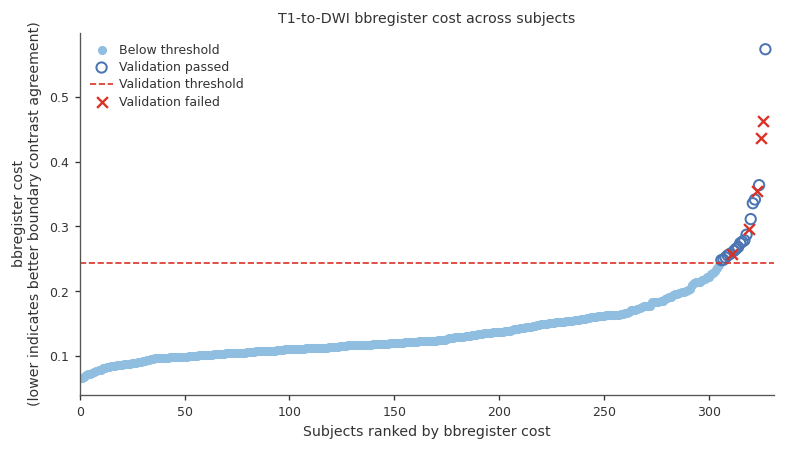

In [8]:
valid = (
    registration_costs.loc[registration_costs["mincost_valid"]]
    .sort_values("bbregister_mincost")
    .copy()
)
valid["rank"] = np.arange(1, len(valid) + 1)

excluded = valid["plot_status"].eq("excluded/fail")
flagged = valid["automatic_cost_outlier"] & ~excluded
passed = ~flagged & ~excluded

costs = valid["bbregister_mincost"]
median_cost = costs.median()
mad_cost = np.median(np.abs(costs - median_cost))
robust_z_threshold = registration_summary.iloc[0]["robust_z_threshold"]
flag_threshold = (
    median_cost + robust_z_threshold * mad_cost / 0.6745
)

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.scatter(
    valid.loc[passed, "rank"],
    valid.loc[passed, "bbregister_mincost"],
    color=PALETTE["light_blue"],
    s=20,
    label="Below threshold",
)
ax.scatter(
    valid.loc[flagged, "rank"],
    valid.loc[flagged, "bbregister_mincost"],
    facecolors="none",
    edgecolors=PALETTE["blue"],
    linewidths=1.2,
    s=38,
    label="Validation passed",
)
ax.axhline(
    flag_threshold,
    color=PALETTE["red"],
    linestyle="--",
    linewidth=1,
    label="Validation threshold",
)
ax.scatter(
    valid.loc[excluded, "rank"],
    valid.loc[excluded, "bbregister_mincost"],
    color=PALETTE["red"],
    marker="x",
    linewidths=1.4,
    s=42,
    label="Validation failed",
)
ax.set(
    title="T1-to-DWI bbregister cost across subjects",
    xlabel="Subjects ranked by bbregister cost",
    ylabel=(
        "bbregister cost\n"
        "(lower indicates better boundary contrast agreement)"
    ),
    xlim=(0, len(valid) + 4),
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    frameon=False,
    fontsize=7.5,
    handlelength=1.8,
    handletextpad=.5,
    labelspacing=.35,
    loc="upper left",
)
fig.tight_layout()
fig.subplots_adjust(left=0.18)
plt.show()


### Figure 2C supplementary distributions

The histogram and boxplot summarize the cohort cost distribution. These plots supplement the ranked subject-level Figure 2C and do not replace subject-level visual review.

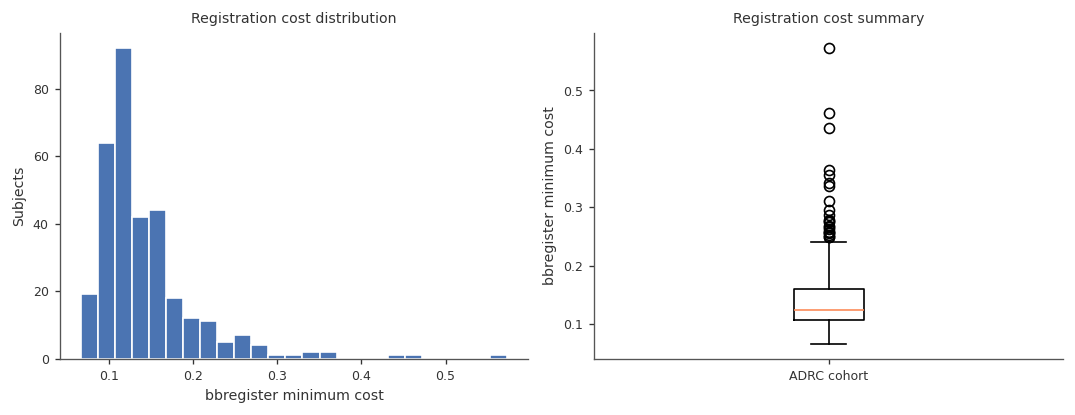

In [9]:
valid_registration_costs = registration_costs.loc[
    registration_costs['mincost_valid'],
    'bbregister_mincost',
]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(
    valid_registration_costs,
    bins=25,
    color='#4B74B2',
    edgecolor='white',
)
axes[0].set(
    title='Registration cost distribution',
    xlabel='bbregister minimum cost',
    ylabel='Subjects',
)
axes[1].boxplot(
    valid_registration_costs,
    showfliers=True,
)
axes[1].set(
    title='Registration cost summary',
    ylabel='bbregister minimum cost',
    xticks=[1],
    xticklabels=['ADRC cohort'],
)
for axis in axes:
    axis.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

### Visual review queue and registration-QC result

The review queue contains robust cost outliers, the highest-cost subjects, missing or ambiguous outputs, manual review/fail entries, and final exclusions. Freeview commands are saved in `qc/freeview_registration_review_commands.sh`. Final exclusion status comes only from the manual registration-QC table.

In [10]:
registration_median_cost = registration_costs.loc[
    registration_costs['mincost_valid'], 'bbregister_mincost'
].median()

figure2c_outlier_costs = (
    registration_costs.loc[
        registration_costs['automatic_cost_outlier'],
        ['subject_id', 'bbregister_mincost', 'robust_z'],
    ]
    .sort_values('bbregister_mincost', ascending=False)
    .rename(columns={'bbregister_mincost': 'cost'})
    .reset_index(drop=True)
)
figure2c_outlier_costs.index = figure2c_outlier_costs.index + 1
figure2c_outlier_costs.index.name = 'cost_rank'

figure2c_median_controls = (
    registration_costs.loc[
        registration_costs['mincost_valid']
        & ~registration_costs['automatic_cost_outlier'],
        ['subject_id', 'bbregister_mincost'],
    ]
    .assign(
        absolute_distance_from_median=lambda table: (
            table['bbregister_mincost'] - registration_median_cost
        ).abs()
    )
    .sort_values(['absolute_distance_from_median', 'subject_id'])
    .head(3)
    .rename(columns={'bbregister_mincost': 'cost'})
    .reset_index(drop=True)
)

display(Markdown('#### 22 automatic cost outliers (descending cost)'))
display(figure2c_outlier_costs.round(6))
display(Markdown(
    f'#### Three non-outlier controls closest to cohort median '
    f'({registration_median_cost:.6f})'
))
display(figure2c_median_controls.round(6))

#### 22 automatic cost outliers (descending cost)

,subject_id,cost,robust_z
cost_rank,,,
1,D0061,0.573075,13.070254
2,D0163,0.461799,9.835654
3,D0128,0.435784,9.079443
4,D0138,0.363678,6.983447
5,D0388,0.354950,6.729739
6,D0370,0.341537,6.339847
7,D0191,0.335794,6.172907
8,D0285,0.311356,5.462537
9,D0248,0.295549,5.003055


#### Three non-outlier controls closest to cohort median (0.123435)

,subject_id,cost,absolute_distance_from_median
0,D0156,0.123435,0.000000
1,D0162,0.123442,0.000007
2,D0187,0.123469,0.000034


In [11]:
summary = registration_summary.iloc[0]
review_cross_tab = pd.crosstab(
    registration_costs['automatic_cost_outlier'],
    registration_costs['final_registration_status'],
)
display(review_cross_tab)
display(registration_review_queue)

registration_result = (
    f"T1–DWI registration costs were available for "
    f"{int(summary['n_with_readable_mincost'])} of "
    f"{int(summary['n_expected_subjects'])} subjects. The median "
    f"boundary-based cost was {summary['median_cost']:.4f}, with an "
    f"interquartile range of {summary['q25_cost']:.4f}–"
    f"{summary['q75_cost']:.4f}. "
    f"{int(summary['n_automatic_cost_outliers'])} subjects were "
    f"flagged as robust cost outliers and referred for visual "
    f"inspection. {int(summary['n_visually_reviewed'])} subjects "
    f"have completed visual review, and "
    f"{int(summary['n_excluded'])} were ultimately excluded. "
    f"Missing or invalid costs were present for "
    f"{int(summary['n_missing_or_invalid_cost'])} subjects. "
    f"{int(summary['n_outliers_excluded'])} automatic outliers "
    f"were also final exclusions. Boundary-based cost was treated "
    f"as a dimensionless QC measure rather than a displacement in "
    f"millimeters."
)
display(Markdown(registration_result))

final_registration_status,excluded,not_reviewed
automatic_cost_outlier,,
False,0,305
True,5,17


,subject_id,cost,robust_z,automatic_cost_outlier,visual_qc_status,reason_for_review,transform_path,moving_image_path,freesurfer_subject_dir
0,D0007,0.268341,4.212166,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
1,D0061,0.573075,13.070254,True,not_reviewed,automatic_cost_outlier;top_10_cost,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
2,D0062,0.255424,3.836691,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
3,D0072,0.262445,4.040779,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
4,D0083,0.257515,3.897473,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
5,D0087,0.248718,3.641759,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
6,D0128,0.435784,9.079443,True,fail,automatic_cost_outlier;top_10_cost;visual_qc_f...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
7,D0138,0.363678,6.983447,True,not_reviewed,automatic_cost_outlier;top_10_cost,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
8,D0145,0.265556,4.131211,True,not_reviewed,automatic_cost_outlier,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...
9,D0163,0.461799,9.835654,True,fail,automatic_cost_outlier;top_10_cost;visual_qc_f...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/results/...,/mnt/newStor/paros/paros_WORK/xintong/data/pro...


T1–DWI registration costs were available for 327 of 327 subjects. The median boundary-based cost was 0.1234, with an interquartile range of 0.1066–0.1603. 22 subjects were flagged as robust cost outliers and referred for visual inspection. 5 subjects have completed visual review, and 5 were ultimately excluded. Missing or invalid costs were present for 0 subjects. 5 automatic outliers were also final exclusions. Boundary-based cost was treated as a dimensionless QC measure rather than a displacement in millimeters.

### Figure 2C interpretation limits

- Boundary-based cost is an optimization score, not a distance in millimeters.
- Cost is affected by image contrast, SNR, acquisition protocol, and residual distortion.
- An unusual cost does not by itself establish registration failure, and a typical cost does not rule out local misregistration.
- Final exclusion requires visual inspection of the registered diffusion reference and white surfaces.
- Figure 2C evaluates the shared T1-to-DWI registration and is independent of the O2/O3 method comparison.

## 12. Figure 2A/B QC summary and automated results

The following text is generated directly from the current tables. No numerical conclusion is hard-coded.

In [12]:
result_lines = []
surface_rows = []
for comparison, label in COMPARISONS.items():
    comparison_coverage = coverage.loc[coverage['comparison'].eq(comparison)]
    included_subjects = comparison_coverage.loc[
        comparison_coverage['n_pairwise_valid'].gt(0),
        'subject_id',
    ].nunique()

    surface_values = []
    for hemisphere in HEMISPHERES:
        surface = load_surface_summary(comparison, hemisphere)
        eligible = surface['valid_subject_fraction'].ge(
            MIN_VALID_SUBJECT_FRACTION
        )
        surface_values.append(
            surface.loc[eligible, 'mean_profile_r_fisher'].dropna()
        )
    pooled_r = pd.concat(surface_values, ignore_index=True)

    bins = (
        curvature_summary.loc[curvature_summary['comparison'].eq(comparison)]
        .sort_values('curvature_bin')
    )
    lowest_mae = bins.iloc[0]['median_mae_across_subjects']
    highest_mae = bins.iloc[-1]['median_mae_across_subjects']
    direction = 'increased' if highest_mae > lowest_mae else 'decreased'

    surface_rows.append(
        {
            'comparison': label,
            'median_surface_r': pooled_r.median(),
            'q25_surface_r': pooled_r.quantile(0.25),
            'q75_surface_r': pooled_r.quantile(0.75),
            'lowest_curvature_bin_mae': lowest_mae,
            'highest_curvature_bin_mae': highest_mae,
        }
    )
    result_lines.append(
        (
            f'**{label}** included {included_subjects} subjects. '
            f'Mean pairwise coverage was '
            f'{comparison_coverage.pairwise_valid_percentage.mean():.2f}% '
            f'(minimum {comparison_coverage.pairwise_valid_percentage.min():.2f}%). '
            f'Across eligible fsaverage vertices, the median Fisher-averaged '
            f'profile correlation was {pooled_r.median():.4f} '
            f'(IQR {pooled_r.quantile(0.25):.4f}–'
            f'{pooled_r.quantile(0.75):.4f}). Median profile MAE {direction} '
            f'from {lowest_mae:.6g} in the lowest-curvature bin to '
            f'{highest_mae:.6g} in the highest-curvature bin.'
        )
    )

display(pd.DataFrame(surface_rows).round(6))
display(Markdown('\n\n'.join(result_lines)))

coverage_pivot = coverage.pivot_table(
    index=['subject_id', 'hemisphere'],
    columns='comparison',
    values='pairwise_valid_percentage',
)
coverage_difference = (
    coverage_pivot['O2Column_vs_O3']
    - coverage_pivot['O2FS_vs_O3']
).abs()
print(
    'Maximum absolute pairwise-coverage difference between comparisons: '
    f'{coverage_difference.max():.3f} percentage points'
)
print(
    'Undefined profile correlations: '
    f"{coverage['n_undefined_profile_correlation'].sum():,}"
)

,comparison,median_surface_r,q25_surface_r,q75_surface_r,lowest_curvature_bin_mae,highest_curvature_bin_mae
0,O2-Column vs O3,0.995823,0.993753,0.997171,0.000015,0.000018
1,O2-FS vs O3,0.859149,0.782282,0.905810,0.000119,0.000145


**O2-Column vs O3** included 50 subjects. Mean pairwise coverage was 98.30% (minimum 80.14%). Across eligible fsaverage vertices, the median Fisher-averaged profile correlation was 0.9958 (IQR 0.9938–0.9972). Median profile MAE increased from 1.47117e-05 in the lowest-curvature bin to 1.82606e-05 in the highest-curvature bin.

**O2-FS vs O3** included 50 subjects. Mean pairwise coverage was 98.71% (minimum 90.13%). Across eligible fsaverage vertices, the median Fisher-averaged profile correlation was 0.8591 (IQR 0.7823–0.9058). Median profile MAE increased from 0.000119438 in the lowest-curvature bin to 0.000144962 in the highest-curvature bin.

Maximum absolute pairwise-coverage difference between comparisons: 19.306 percentage points
Undefined profile correlations: 12,706


### Three-method common-mask sensitivity check

Because one subject-hemisphere shows a noticeable difference between the two pairwise coverage estimates, the key profile-correlation and MAE summaries are repeated using the three-method common mask. The table below uses one median value per subject, so subjects remain the statistical units.

In [13]:
def summarize_masks_by_subject(comparison):
    path = OUTPUT_DIR / f'figure2_{comparison}_vertex_metrics.parquet'
    parquet_file = pq.ParquetFile(path)
    rows = []
    current_subject = None
    subject_frames = []

    def finish_subject(subject_id, frames):
        if subject_id is None:
            return
        subject_data = pd.concat(frames, ignore_index=True)
        for mask_type, mask_column in (
            ('pairwise', 'pairwise_valid'),
            ('three_method_common', 'three_method_common_valid'),
        ):
            valid = (
                subject_data[mask_column].astype(bool)
                & subject_data['profile_r'].notna()
                & subject_data['profile_mae'].notna()
            )
            rows.append(
                {
                    'comparison': comparison,
                    'subject_id': subject_id,
                    'mask_type': mask_type,
                    'n_vertices': int(valid.sum()),
                    'median_profile_r': subject_data.loc[
                        valid,
                        'profile_r',
                    ].median(),
                    'median_profile_mae': subject_data.loc[
                        valid,
                        'profile_mae',
                    ].median(),
                }
            )

    columns = [
        'subject_id',
        'profile_r',
        'profile_mae',
        'pairwise_valid',
        'three_method_common_valid',
    ]
    for row_group_index in range(parquet_file.num_row_groups):
        frame = parquet_file.read_row_group(
            row_group_index,
            columns=columns,
        ).to_pandas()
        subject_id = frame['subject_id'].iloc[0]
        if current_subject is not None and subject_id != current_subject:
            finish_subject(current_subject, subject_frames)
            subject_frames = []
        current_subject = subject_id
        subject_frames.append(frame)
    finish_subject(current_subject, subject_frames)
    return pd.DataFrame(rows)


mask_sensitivity_subject = pd.concat(
    [summarize_masks_by_subject(name) for name in COMPARISONS],
    ignore_index=True,
)
mask_sensitivity_summary = (
    mask_sensitivity_subject.groupby(
        ['comparison', 'mask_type'],
        as_index=False,
    )
    .agg(
        n_subjects=('subject_id', 'nunique'),
        median_subject_profile_r=('median_profile_r', 'median'),
        q25_subject_profile_r=(
            'median_profile_r',
            lambda values: values.quantile(0.25),
        ),
        q75_subject_profile_r=(
            'median_profile_r',
            lambda values: values.quantile(0.75),
        ),
        median_subject_profile_mae=('median_profile_mae', 'median'),
        q25_subject_profile_mae=(
            'median_profile_mae',
            lambda values: values.quantile(0.25),
        ),
        q75_subject_profile_mae=(
            'median_profile_mae',
            lambda values: values.quantile(0.75),
        ),
    )
)
mask_sensitivity_subject.to_csv(
    OUTPUT_DIR / 'figure2_mask_sensitivity_subject_summary.csv',
    index=False,
)
mask_sensitivity_summary.to_csv(
    OUTPUT_DIR / 'figure2_mask_sensitivity_cross_subject_summary.csv',
    index=False,
)
display(mask_sensitivity_summary.round(6))

coverage_outliers = coverage_pivot.assign(
    absolute_difference_percentage_points=coverage_difference
).loc[coverage_difference.gt(5.0)]
display(coverage_outliers.round(3))

,comparison,mask_type,n_subjects,median_subject_profile_r,q25_subject_profile_r,q75_subject_profile_r,median_subject_profile_mae,q25_subject_profile_mae,q75_subject_profile_mae
0,O2Column_vs_O3,pairwise,50,0.996497,0.995349,0.997169,0.000015,0.000014,0.000018
1,O2Column_vs_O3,three_method_common,50,0.996497,0.995349,0.997169,0.000015,0.000014,0.000018
2,O2FS_vs_O3,pairwise,50,0.870392,0.845704,0.902817,0.000123,0.000115,0.000142
3,O2FS_vs_O3,three_method_common,50,0.870605,0.845955,0.903009,0.000123,0.000115,0.000142


,comparison,O2Column_vs_O3,O2FS_vs_O3,absolute_difference_percentage_points
subject_id,hemisphere,,,
D0061,rh,80.136,99.442,19.306


## 13. Main conclusions and limitations

Interpret the automatically generated results above with five considerations:

1. Compare profile-shape agreement for O2-Column and O2-FS relative to O3.
2. Determine whether profile MAE rises across curvature bins.
3. Assess whether O2-FS and O2-Column differ in their curvature dependence.
4. Check whether coverage, undefined correlations, or isolated subjects could explain the pattern.
5. Use the independent registration QC to identify subjects requiring T1-to-DWI overlay review.

This notebook does not address general diffusion image-quality QC, regional analysis, depth-specific MAE curves, or disease-group inference.